# Forecasting California Gasoline Prices — 時間序列與預測模型

這份 notebook 依照 *Project Proposal: Forecasting California Gasoline Prices* 的 Methodology 一步步跑：

| Section | 內容 | Proposal |
|---|---|---|
| 0 | 設定、讀取 `data/weekly_data.csv` | 1. Data preparation |
| 1 | EDA：價格、價差、STL、ADF/KPSS、ACF/PACF、原油領先性 | 2. Exploratory analysis |
| 2 | Train/test 切分 + rolling-origin backtest 框架 | 3. Test design |
| 3 | 傳統模型：Naive、Seasonal naive、ETS、ARIMA+Fourier、ARIMAX | 4. Conventional models |
| 4 | 評估：MAE/RMSE/MAPE、skill vs naive、Diebold-Mariano、80% 區間覆蓋率、forecast combination | 6. Evaluation |
| 5 | VAR、Granger causality、impulse response | 4. VAR |
| 6 | Rockets and feathers：非對稱 error-correction model | 4. Asymmetry test |
| 3.5, 7 | **AI 模型**：Chronos、TimesFM、LLM（Claude、ChatGPT），AI vs 傳統模型 | 5. AI models |
| 8 | **情境預測**：有事件 vs 沒有事件（戰爭、煉油廠事故）、Brent 價格情境 `scenario()` | 7. Dashboard scenario tool |

**先跑 `data_pull.py`** 產生 `data/weekly_data.csv`。所有預測都存成 proposal 指定的統一格式：
`model, origin_date, horizon, target_date, forecast, lower80, upper80`（存在 `forecasts/`）。

## 0. 設定與資料

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.api import VAR

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("data/weekly_data.csv")
FC_DIR = Path("forecasts"); FC_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

TRAIN_END = "2025-06-30"   # last training week (proposal: train Jan 2000 - Jun 2025)
H = 12                     # forecast 1-12 weeks ahead
SCORE_H = [4, 12]          # horizons we score
Z80 = stats.norm.ppf(0.9)  # 80% interval -> +/- 1.2816 sd
PERIOD = 365.25 / 7        # weekly seasonal period (~52.18)

df = pd.read_csv(DATA, index_col="date", parse_dates=True).asfreq("W-MON")
print(df.shape, df.index.min().date(), "->", df.index.max().date())
df.tail(3)

(1377, 22) 2000-05-22 -> 2026-10-05


,ca_gas,us_gas,wti,brent,refinery_util_padd5,gas_stocks_padd5,refinery_util_us,gas_stocks_us,spread,log_ca_gas,...,log_brent,summer_blend,july_tax,covid,p66_la_closed,benicia_closed,chevron_es_fire,iraq_war,ukraine_war,iran_war_2026
date,,,,,,,,,,,,,,,,,,,,,
2026-09-21,6.003,4.478,103.542,124.146,94.9,27386,96.8,207732,1.525,1.792259,...,4.821458,1,0,0,1,1,0,0,0,1
2026-09-28,6.189,4.465,93.574,117.084,94.5,27328,94.0,206046,1.724,1.822774,...,4.762892,1,0,0,1,1,0,0,0,1
2026-10-05,6.227,4.354,98.074,120.034,93.4,27990,92.5,204362,1.873,1.828895,...,4.787775,1,0,0,1,1,0,0,0,1


## 1. Exploratory analysis
### 1.1 加州 vs 全美油價、價差、原油

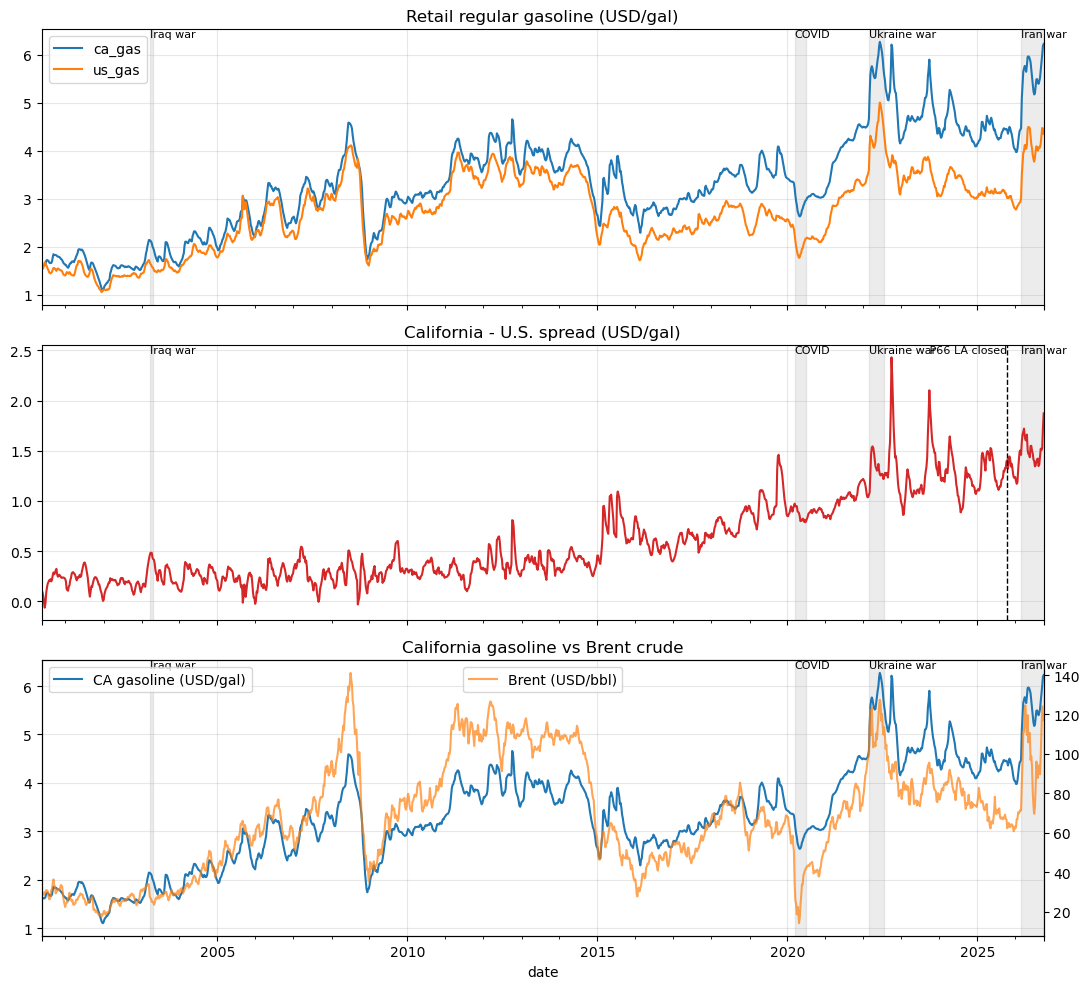

In [2]:
EVENTS = {  # shaded on the charts
    "Iraq war": ("2003-03-24", "2003-04-28"), "COVID": ("2020-03-16", "2020-06-30"),
    "Ukraine war": ("2022-02-28", "2022-07-25"), "Iran war": ("2026-03-02", df.index.max()),
}

def shade(ax):
    for name, (a, b) in EVENTS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15)
        ax.text(pd.Timestamp(a), ax.get_ylim()[1], name, fontsize=8, va="top")

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
df[["ca_gas", "us_gas"]].plot(ax=axes[0], title="Retail regular gasoline (USD/gal)")
df["spread"].plot(ax=axes[1], color="C3", title="California - U.S. spread (USD/gal)")
axes[1].axvline(pd.Timestamp("2025-10-20"), color="k", ls="--", lw=1)
axes[1].text(pd.Timestamp("2025-10-20"), axes[1].get_ylim()[1], " P66 LA closed", fontsize=8, va="top", ha="right")
ax2 = axes[2]; df["ca_gas"].plot(ax=ax2, color="C0", label="CA gasoline (USD/gal)")
ax2b = ax2.twinx(); df["brent"].plot(ax=ax2b, color="C1", alpha=0.7, label="Brent (USD/bbl)")
ax2.set_title("California gasoline vs Brent crude"); ax2b.grid(False)
ax2.legend(loc="upper left"); ax2b.legend(loc="upper center")
for ax in axes: shade(ax)
plt.tight_layout(); plt.show()

### 1.2 STL 分解（52 週季節）→ 夏季價格溢價

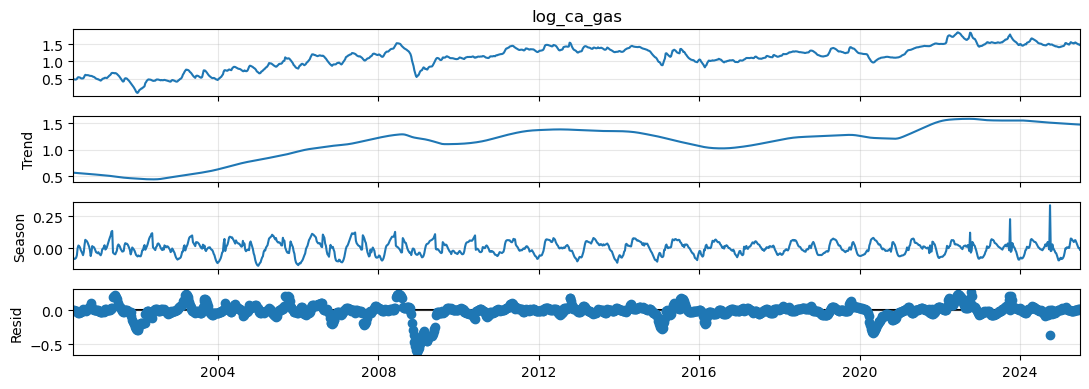

Summer (Apr-Oct) vs winter seasonal premium: 6.2%


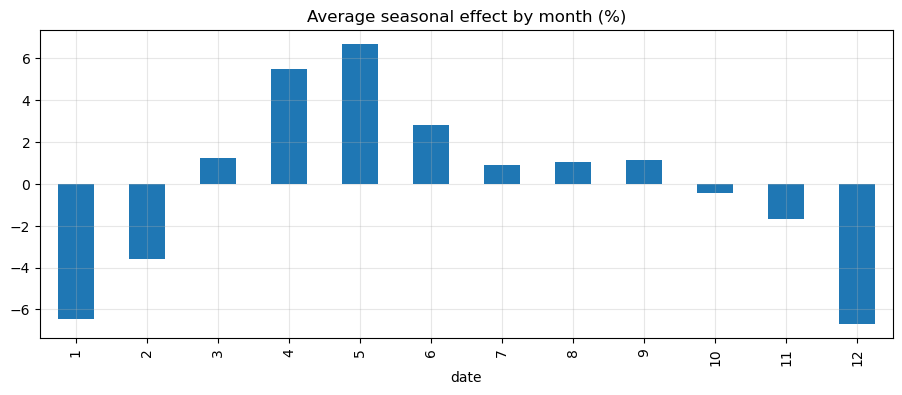

In [3]:
train = df.loc[:TRAIN_END]
stl = STL(train["log_ca_gas"], period=52, robust=True).fit()
stl.plot(); plt.show()

seas = stl.seasonal.groupby(stl.seasonal.index.month).mean()
premium = np.exp(seas.loc[4:10].mean() - seas.drop(range(4, 11)).mean()) - 1
print(f"Summer (Apr-Oct) vs winter seasonal premium: {premium:.1%}")
(np.exp(seas) - 1).mul(100).plot(kind="bar", title="Average seasonal effect by month (%)"); plt.show()

### 1.3 單根檢定（ADF / KPSS）
- ADF：H0 = 有單根（非定態）→ p < 0.05 表示定態
- KPSS：H0 = 定態 → p < 0.05 表示非定態

兩者都指向「水準非定態、一階差分定態」就用 d = 1。

In [4]:
def unit_root_table(series_dict):
    rows = []
    for name, s in series_dict.items():
        s = s.dropna()
        rows.append({"series": name,
                     "ADF p": adfuller(s, autolag="AIC")[1],
                     "KPSS p": kpss(s, regression="c", nlags="auto")[1]})
    return pd.DataFrame(rows).set_index("series").round(3)

unit_root_table({
    "log_ca_gas": train["log_ca_gas"], "diff log_ca_gas": train["log_ca_gas"].diff(),
    "log_brent": train["log_brent"], "diff log_brent": train["log_brent"].diff(),
    "spread": train["spread"],
})

,ADF p,KPSS p
series,,
log_ca_gas,0.142,0.01
diff log_ca_gas,0.000,0.10
log_brent,0.117,0.01
diff log_brent,0.000,0.10
spread,0.734,0.01


### 1.4 ACF / PACF（Δlog 加州油價）→ ARIMA 階數參考

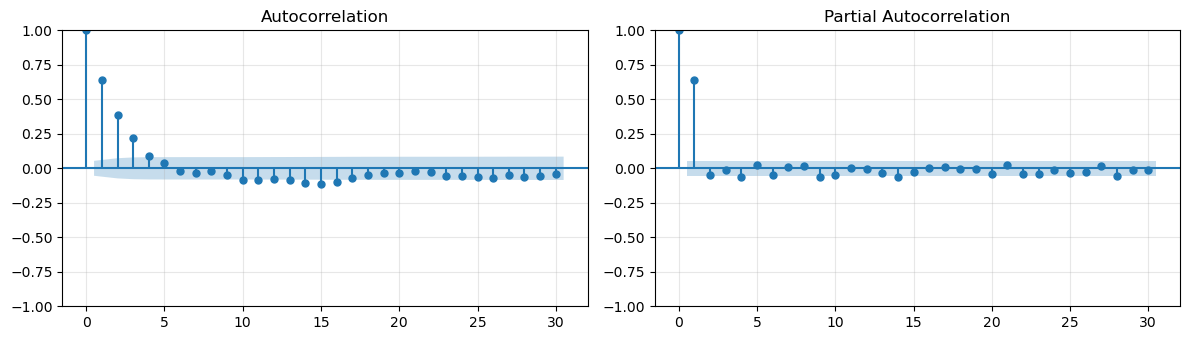

In [5]:
dy = train["log_ca_gas"].diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(dy, lags=30, ax=axes[0]); plot_pacf(dy, lags=30, ax=axes[1], method="ywm")
plt.tight_layout(); plt.show()

### 1.5 原油領先油價幾週？（cross-correlation of weekly changes）

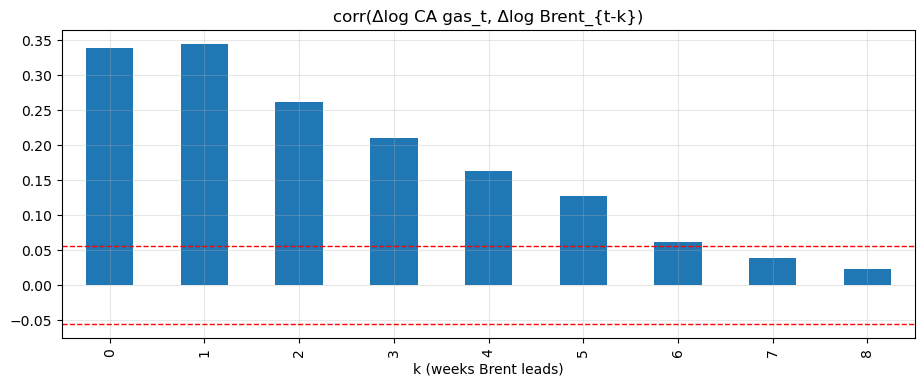

0    0.339
1    0.345
2    0.261
3    0.211
4    0.163
5    0.127
6    0.061
7    0.038
8    0.023


In [6]:
dc = train["log_brent"].diff().dropna()
dy, dc = dy.align(dc, join="inner")
# corr(dy_t, dc_{t-k}) for k = 0..8
xc = pd.Series([dy.corr(dc.shift(k)) for k in range(9)], index=range(9))
ax = xc.plot(kind="bar", title="corr(Δlog CA gas_t, Δlog Brent_{t-k})")
ax.axhline(2 / np.sqrt(len(dy)), color="r", ls="--", lw=1); ax.axhline(-2 / np.sqrt(len(dy)), color="r", ls="--", lw=1)
ax.set_xlabel("k (weeks Brent leads)"); plt.show()
print(xc.round(3).to_string())

## 2. Test design：rolling origin（expanding window）

- **Training**：2000 年 ~ 2025-06-30；**Test**：2025-07 ~ 最新一週
- 每個 origin（每一個 test 週）只用 origin 之前的資料重新 fit，預測 1–12 週，之後評分 h = 4 和 h = 12
- **不使用未來資訊**：ARIMAX 的未來 Brent 用 random walk（= origin 當週最後觀察值）；事件 dummy 維持 origin 當時的值；只有月曆型 dummy（summer_blend、july_tax）事先就知道

每個模型只需要寫一個 `fit_forecast(train, H)`，回傳 index 為 horizon 1..H、欄位為 `forecast, lower80, upper80`（USD/gal）的 DataFrame，就能丟進 `backtest()`。

In [7]:
ORIGINS = df.loc[TRAIN_END:].index[:-1]   # last week has nothing left to score
print(f"{len(ORIGINS)} origins: {ORIGINS[0].date()} -> {ORIGINS[-1].date()}")


def backtest(name, fit_forecast, origins=ORIGINS, h=H, verbose=True):
    # Run fit_forecast at every origin and save forecasts in the shared format.
    out = []
    for i, origin in enumerate(origins):
        fc = fit_forecast(df.loc[:origin], h).copy()
        fc["horizon"] = range(1, h + 1)
        fc["origin_date"] = origin
        fc["target_date"] = origin + pd.to_timedelta(7 * fc["horizon"], unit="D")
        out.append(fc)
        if verbose and (i % 20 == 0 or i == len(origins) - 1):
            print(f"  {name}: origin {i + 1}/{len(origins)} {origin.date()}")
    out = pd.concat(out, ignore_index=True)
    out.insert(0, "model", name)
    out = out[["model", "origin_date", "horizon", "target_date", "forecast", "lower80", "upper80"]]
    out.to_csv(FC_DIR / f"{name}.csv", index=False)
    return out


def from_log(mean, sd=None, lower=None, upper=None):
    # Log-scale forecast -> USD/gal (exp of the log forecast = median).
    if sd is not None:
        lower, upper = mean - Z80 * sd, mean + Z80 * sd
    return pd.DataFrame({"forecast": np.exp(np.asarray(mean)),
                         "lower80": np.exp(np.asarray(lower)),
                         "upper80": np.exp(np.asarray(upper))}, index=range(1, len(mean) + 1))

forecasts = {}

66 origins: 2025-06-30 -> 2026-09-28


## 3. 傳統模型
### 3.1 Naive benchmarks（每個模型都必須贏過這兩個）
- **Naive**：預測 = 上週價格；80% 區間用訓練期週變動標準差 × √h
- **Seasonal naive**：預測 = 52 週前的價格

In [8]:
def naive_ff(train, h):
    y = train["log_ca_gas"]
    sd = y.diff().std()
    return from_log(np.repeat(y.iloc[-1], h), sd=sd * np.sqrt(np.arange(1, h + 1)))

def snaive_ff(train, h):
    y = train["log_ca_gas"]
    sd = y.diff(52).std()
    return from_log(y.iloc[-52:-52 + h].values, sd=np.repeat(sd, h))  # target t+h <- week t+h-52

forecasts["naive"] = backtest("naive", naive_ff)
forecasts["snaive"] = backtest("snaive", snaive_ff)

  naive: origin 1/66 2025-06-30
  naive: origin 21/66 2025-11-17
  naive: origin 41/66 2026-04-06
  naive: origin 61/66 2026-08-24
  naive: origin 66/66 2026-09-28
  snaive: origin 1/66 2025-06-30
  snaive: origin 21/66 2025-11-17
  snaive: origin 41/66 2026-04-06
  snaive: origin 61/66 2026-08-24
  snaive: origin 66/66 2026-09-28


### 3.2 ETS（指數平滑）
在 training set 上用 AICc 選趨勢型態（無趨勢 / 加法趨勢 / 阻尼趨勢），之後每個 origin 用同樣的設定重新 fit。

In [9]:
y_train = train["log_ca_gas"]
ets_specs = {"ANN": dict(trend=None), "AAN": dict(trend="add"), "AAdN": dict(trend="add", damped_trend=True)}
ets_aicc = {k: ETSModel(y_train, error="add", **v).fit(disp=False).aicc for k, v in ets_specs.items()}
print(pd.Series(ets_aicc).round(1).to_string())
ETS_SPEC = ets_specs[min(ets_aicc, key=ets_aicc.get)]
print("Chosen:", min(ets_aicc, key=ets_aicc.get))

def ets_ff(train, h):
    y = train["log_ca_gas"]
    res = ETSModel(y, error="add", **ETS_SPEC).fit(disp=False)
    pr = res.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)
    return from_log(pr["mean"], lower=pr["pi_lower"], upper=pr["pi_upper"])

forecasts["ets"] = backtest("ets", ets_ff)

ANN    -6187.6
AAN    -6664.9
AAdN   -6841.5
Chosen: AAdN


  ets: origin 1/66 2025-06-30


  ets: origin 21/66 2025-11-17


  ets: origin 41/66 2026-04-06


  ets: origin 61/66 2026-08-24


  ets: origin 66/66 2026-09-28


### 3.3 ARIMA + Fourier terms
log 價格的 ARIMA(p,1,q)，外加 K 組 52 週 Fourier 項（sin/cos）代表季節性，比 period = 52 的 seasonal ARIMA 穩定。

**選模**：在 training set 上先用 ARIMA(1,1,1) 以 AIC 選 K，再用 AIC 選 p, q ∈ {0..3}。之後每個 origin 用同樣的階數重新估計參數（自動選模每週重跑太慢，也讓結果較穩定）。

In [10]:
T0 = df.index[0]

def fourier(dates, K):
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD)
                         for k in range(1, K + 1) for f, fn in (("sin", np.sin), ("cos", np.cos))}, index=dates)

def fit_sarimax(y, X, order, start_params=None):
    return SARIMAX(y, exog=X, order=order, trend="n").fit(disp=False, start_params=start_params, maxiter=200)

aic_K = {K: fit_sarimax(y_train, fourier(y_train.index, K), (1, 1, 1)).aic for K in range(1, 5)}
K_BEST = min(aic_K, key=aic_K.get)
print("AIC by K:", {k: round(v, 1) for k, v in aic_K.items()}, "-> K =", K_BEST)

aic_pq = {(p, q): fit_sarimax(y_train, fourier(y_train.index, K_BEST), (p, 1, q)).aic
          for p in range(4) for q in range(4)}
p_best, q_best = min(aic_pq, key=aic_pq.get)
ORDER = (p_best, 1, q_best)
print("Chosen ARIMA order:", ORDER)

AIC by K: {1: np.float64(-6904.3), 2: np.float64(-6929.2), 3: np.float64(-6931.5), 4: np.float64(-6928.6)} -> K = 3


Chosen ARIMA order: (3, 1, 2)


In [11]:
def future_dates(train, h):
    return pd.date_range(train.index[-1] + pd.Timedelta(days=7), periods=h, freq="W-MON")

def make_arima_ff():
    state = {}
    def ff(train, h):
        y = train["log_ca_gas"]
        res = fit_sarimax(y, fourier(y.index, K_BEST), ORDER, state.get("params"))
        state["params"] = res.params
        pr = res.get_forecast(h, exog=fourier(future_dates(train, h), K_BEST)).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

forecasts["arima_fourier"] = backtest("arima_fourier", make_arima_ff())

  arima_fourier: origin 1/66 2025-06-30


  arima_fourier: origin 21/66 2025-11-17


  arima_fourier: origin 41/66 2026-04-06


  arima_fourier: origin 61/66 2026-08-24


  arima_fourier: origin 66/66 2026-09-28


### 3.4 ARIMAX：ARIMA + Fourier + Brent + 事件 dummy

- **Brent**：放 `log_brent` 的 1–4 週落後**水準**。因為模型是 d = 1（regression with ARIMA errors，y 和 X 一起差分），等同於「Δlog 油價 對 Δlog Brent 落後 1–4 週」，也就是 proposal 的 lagged weekly changes。
- **未來 Brent**：random walk，未來的 log Brent = origin 當週的值 → ARIMAX 沒有偷看未來原油價。
- **Dummy**：`summer_blend`、`july_tax` 是月曆型，未來值可以直接算；其他事件 dummy 在未來維持 origin 當週的值。在 training 資料中沒有變化的 dummy（例如 2025-10 之前的 `p66_la_closed`）自動排除。

In [12]:
CAL_DUMMIES = ["summer_blend", "july_tax"]
EVENT_DUMMIES = ["covid", "iraq_war", "ukraine_war", "chevron_es_fire", "p66_la_closed", "benicia_closed", "iran_war_2026"]
BRENT_LAGS = range(1, 5)

def calendar_dummies(dates):
    return pd.DataFrame({"summer_blend": dates.month.isin(range(4, 11)).astype(int),
                         "july_tax": ((dates.month == 7) & (dates.day <= 28)).astype(int)}, index=dates)

def arimax_exog(train, h):
    # Exog for the training sample and for the h future weeks, using only info known at the origin.
    fut = future_dates(train, h)
    lb = pd.concat([train["log_brent"], pd.Series(train["log_brent"].iloc[-1], index=fut)])  # random walk
    lags = pd.DataFrame({f"log_brent_l{k}": lb.shift(k) for k in BRENT_LAGS})
    events = [c for c in EVENT_DUMMIES if train[c].nunique() > 1]
    ev = pd.concat([train[events], pd.DataFrame([train[events].iloc[-1].values] * h, index=fut, columns=events)])
    idx = lags.index
    X = pd.concat([fourier(idx, K_BEST), lags, calendar_dummies(idx), ev], axis=1).iloc[max(BRENT_LAGS):]
    return X.loc[:train.index[-1]], X.loc[fut]

def make_arimax_ff():
    state = {}
    def ff(train, h):
        X, Xf = arimax_exog(train, h)
        y = train["log_ca_gas"].loc[X.index]
        key = tuple(X.columns)  # dummies enter the model over time -> reuse params only if same columns
        res = fit_sarimax(y, X, ORDER, state.get(key))
        state[key] = res.params
        pr = res.get_forecast(h, exog=Xf).summary_frame(alpha=0.2)
        return from_log(pr["mean"], lower=pr["mean_ci_lower"], upper=pr["mean_ci_upper"])
    return ff

forecasts["arimax"] = backtest("arimax", make_arimax_ff())

# Coefficients on the full training sample
X_tr, _ = arimax_exog(train, 1)
arimax_train = fit_sarimax(train["log_ca_gas"].loc[X_tr.index], X_tr, ORDER)
arimax_train.summary().tables[1]

  arimax: origin 1/66 2025-06-30


  arimax: origin 21/66 2025-11-17


  arimax: origin 41/66 2026-04-06


  arimax: origin 61/66 2026-08-24


  arimax: origin 66/66 2026-09-28


,coef,std err,z,P>|z|,[0.025,0.975]
sin1,0.0329,0.012,2.760,0.006,0.010,0.056
cos1,0.0522,0.010,5.430,0.000,0.033,0.071
sin2,-0.0307,0.006,-4.975,0.000,-0.043,-0.019
cos2,0.0081,0.006,1.344,0.179,-0.004,0.020
sin3,0.0076,0.004,1.899,0.058,-0.000,0.015
cos3,-0.0001,0.004,-0.029,0.977,-0.008,0.007
log_brent_l1,0.0752,0.011,6.992,0.000,0.054,0.096
log_brent_l2,0.0634,0.011,5.520,0.000,0.041,0.086
log_brent_l3,0.0574,0.011,5.440,0.000,0.037,0.078
log_brent_l4,0.0308,0.009,3.370,0.001,0.013,0.049


### 3.5 AI 模型（預先算好的預測）
AI 模型需要 PyTorch，所以放在獨立的環境裡跑，結果存成和其他模型同樣格式的 CSV：
- `ai_models.py`：**Chronos-Bolt**、**Chronos-2**（Amazon）、**TimesFM 2.5**（Google），zero-shot（不重新訓練），每個 origin 用最後 512 週當 context
- `llm/llm_experiments.py`：**Claude** 和 **ChatGPT**，每 4 個 test 週一次、每次重複 3 次取平均，分成匿名（anon）與完整背景（context）兩個實驗

這裡把 `forecasts/` 裡的 AI 預測讀進來，之後的評估、DM test、combination 都會自動包含它們。

In [13]:
AI_PREFIXES = ("chronos", "timesfm", "llm_")
is_ai = lambda m: m.startswith(AI_PREFIXES)
for f in sorted(FC_DIR.glob("*.csv")):
    if is_ai(f.stem):
        forecasts[f.stem] = pd.read_csv(f, parse_dates=["origin_date", "target_date"])
print("AI forecasts loaded:", [m for m in forecasts if is_ai(m)] or "none (run ai_models.py first)")

ai_log = RES_DIR / "ai_model_log.csv"
pd.read_csv(ai_log) if ai_log.exists() else None

AI forecasts loaded: ['chronos2', 'chronos_bolt', 'timesfm']


,model,repo,revision,released,release_inside_test_period,context_weeks,run_at,runtime_s
0,chronos_bolt,amazon/chronos-bolt-small,772f3d25d3,2024-11-25,False,512,2026-10-13 14:14,11
1,chronos2,amazon/chronos-2,29ec3766d3,2025-10-30,True,512,2026-10-13 14:15,19
2,timesfm,google/timesfm-2.5-200m-pytorch,1d952420fb,2025-09-02,True,512,2026-10-13 14:15,40


## 4. 評估
- **MAE / RMSE / MAPE**（USD/gal）at h = 4, 12
- **Skill vs naive** = MAE / naive MAE（< 1 表示贏過 naive）
- **Coverage80** = 實際值落在 80% 區間內的比例（理想 ≈ 0.80）
- **Forecast combination**：proposal 的設計，「最好的傳統模型 + 最好的 AI 模型」取平均，測試 AI 是否提供傳統模型沒有的資訊
- LLM 只在每 4 週預測一次，所以它們的 `n` 比較少；公平比較見第 7 節（只用 LLM 有預測的那幾週）

In [14]:
def evaluate(fc_dict):
    all_fc = pd.concat(fc_dict.values(), ignore_index=True)
    all_fc["actual"] = all_fc["target_date"].map(df["ca_gas"])
    all_fc = all_fc.dropna(subset=["actual"])
    all_fc["err"] = all_fc["actual"] - all_fc["forecast"]
    all_fc["covered"] = all_fc["actual"].between(all_fc["lower80"], all_fc["upper80"])
    sc = all_fc[all_fc["horizon"].isin(SCORE_H)].assign(
        abs_err=lambda d: d.err.abs(), sq_err=lambda d: d.err ** 2, ape=lambda d: (d.err / d.actual).abs() * 100)
    m = sc.groupby(["horizon", "model"]).agg(
        n=("err", "size"), MAE=("abs_err", "mean"), RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
        MAPE=("ape", "mean"), Coverage80=("covered", "mean"))
    naive_mae = m["MAE"].xs("naive", level="model")
    m["Skill_vs_naive"] = m["MAE"] / naive_mae.reindex(m.index.get_level_values("horizon")).values
    return all_fc, m.round(3)

all_fc, metrics = evaluate(forecasts)
metrics.sort_values(["horizon", "MAE"])

n    MAE   RMSE    MAPE  Coverage80  Skill_vs_naive
horizon model                                                              
4       arima_fourier  63  0.217  0.312   4.100       0.810           0.804
        arimax         63  0.226  0.326   4.249       0.762           0.837
        timesfm        63  0.256  0.361   4.909       0.746           0.948
        naive          63  0.270  0.384   5.233       0.635           1.000
        chronos2       63  0.273  0.384   5.205       0.730           1.009
        chronos_bolt   63  0.277  0.384   5.308       0.683           1.025
        ets            63  0.281  0.378   5.374       0.841           1.039
        snaive         63  0.631  0.848  11.421       0.841           2.335
12      arima_fourier  55  0.409  0.581   7.511       0.745           0.682
        arimax         55  0.427  0.609   7.775       0.709           0.711
        chronos2       55  0.575  0.818  10.566       0.673           0.959
        chronos_bolt   55  0.579  0.829  10.592       0.691           0.966
        timesfm        55  0.582  0.820  10.697       0.709           0.970
        naive          55  0.600  0.812  11.109       0.673           1.000
        snaive         55  0.715  0.907  12.895       0.818           1.192
        ets            55  0.725  0.904  13.502       0.836           1.208

In [15]:
# Forecast combination: best conventional + best AI model (by h = 4 MAE). Only models that forecast at
# every origin are eligible, so the LLMs (every 4th week) are left out of the combination.
m4 = metrics.xs(4, level="horizon")
full = m4[m4["n"] == m4.loc["naive", "n"]].index
conventional = [m for m in full if not is_ai(m) and m not in ("naive", "snaive", "combo")]
ai_full = [m for m in full if is_ai(m)]
best_conv = m4.loc[conventional, "MAE"].idxmin()
COMBO = [best_conv, m4.loc[ai_full, "MAE"].idxmin()] if ai_full else list(m4.loc[conventional, "MAE"].nsmallest(2).index)
combo = (pd.concat([forecasts[m] for m in COMBO])
         .groupby(["origin_date", "horizon", "target_date"], as_index=False)[["forecast", "lower80", "upper80"]].mean())
combo.insert(0, "model", "combo")
combo.to_csv(FC_DIR / "combo.csv", index=False)
forecasts["combo"] = combo
print("Combination of:", COMBO)

all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.sort_values(["horizon", "MAE"])

Combination of: ['arima_fourier', 'timesfm']


n    MAE   RMSE    MAPE  Coverage80  Skill_vs_naive
horizon model                                                              
4       arima_fourier  63  0.217  0.312   4.100       0.810           0.804
        arimax         63  0.226  0.326   4.249       0.762           0.837
        combo          63  0.227  0.328   4.306       0.825           0.840
        timesfm        63  0.256  0.361   4.909       0.746           0.948
        naive          63  0.270  0.384   5.233       0.635           1.000
        chronos2       63  0.273  0.384   5.205       0.730           1.009
        chronos_bolt   63  0.277  0.384   5.308       0.683           1.025
        ets            63  0.281  0.378   5.374       0.841           1.039
        snaive         63  0.631  0.848  11.421       0.841           2.335
12      arima_fourier  55  0.409  0.581   7.511       0.745           0.682
        arimax         55  0.427  0.609   7.775       0.709           0.711
        combo          55  0.469  0.690   8.501       0.727           0.782
        chronos2       55  0.575  0.818  10.566       0.673           0.959
        chronos_bolt   55  0.579  0.829  10.592       0.691           0.966
        timesfm        55  0.582  0.820  10.697       0.709           0.970
        naive          55  0.600  0.812  11.109       0.673           1.000
        snaive         55  0.715  0.907  12.895       0.818           1.192
        ets            55  0.725  0.904  13.502       0.836           1.208

### 4.1 Diebold-Mariano test
H0：兩個模型預測準確度相同（squared-error loss）。使用 h-1 階 HAC 變異數 + Harvey-Leybourne-Newbold 小樣本修正。DM < 0 表示第一個模型比較準。

In [16]:
def dm_test(e1, e2, h, power=2):
    d = np.abs(e1) ** power - np.abs(e2) ** power
    n, dbar = len(d), d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:  # HAC estimate can turn negative for long horizons -> fall back to plain variance
        var = gamma[0] / n
    dm = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

rows = []
for h in SCORE_H:
    e = all_fc[all_fc.horizon == h].pivot(index="origin_date", columns="model", values="err")
    for m in e.columns:
        for bench in ["naive", best_conv]:
            if m != bench:
                pair = e[[m, bench]].dropna()   # align each pair on the dates both models forecast
                dm, p = dm_test(pair[m].values, pair[bench].values, h)
                rows.append({"horizon": h, "model": m, "vs": bench, "n": len(pair), "DM": dm, "p": p})
dm_table = pd.DataFrame(rows).round(3)
dm_table.to_csv(RES_DIR / "dm_tests.csv", index=False)
print("Best conventional model (h=4 MAE):", best_conv)
dm_table

Best conventional model (h=4 MAE): arima_fourier


,horizon,model,vs,n,DM,p
0,4,arima_fourier,naive,63,-1.436,0.156
1,4,arimax,naive,63,-1.070,0.289
2,4,arimax,arima_fourier,63,1.403,0.166
3,4,chronos2,naive,63,-0.014,0.989
4,4,chronos2,arima_fourier,63,1.913,0.060
5,4,chronos_bolt,naive,63,-0.025,0.980
6,4,chronos_bolt,arima_fourier,63,2.226,0.030
7,4,combo,naive,63,-1.416,0.162
8,4,combo,arima_fourier,63,1.390,0.170
9,4,ets,naive,63,-0.180,0.858


### 4.2 預測 vs 實際

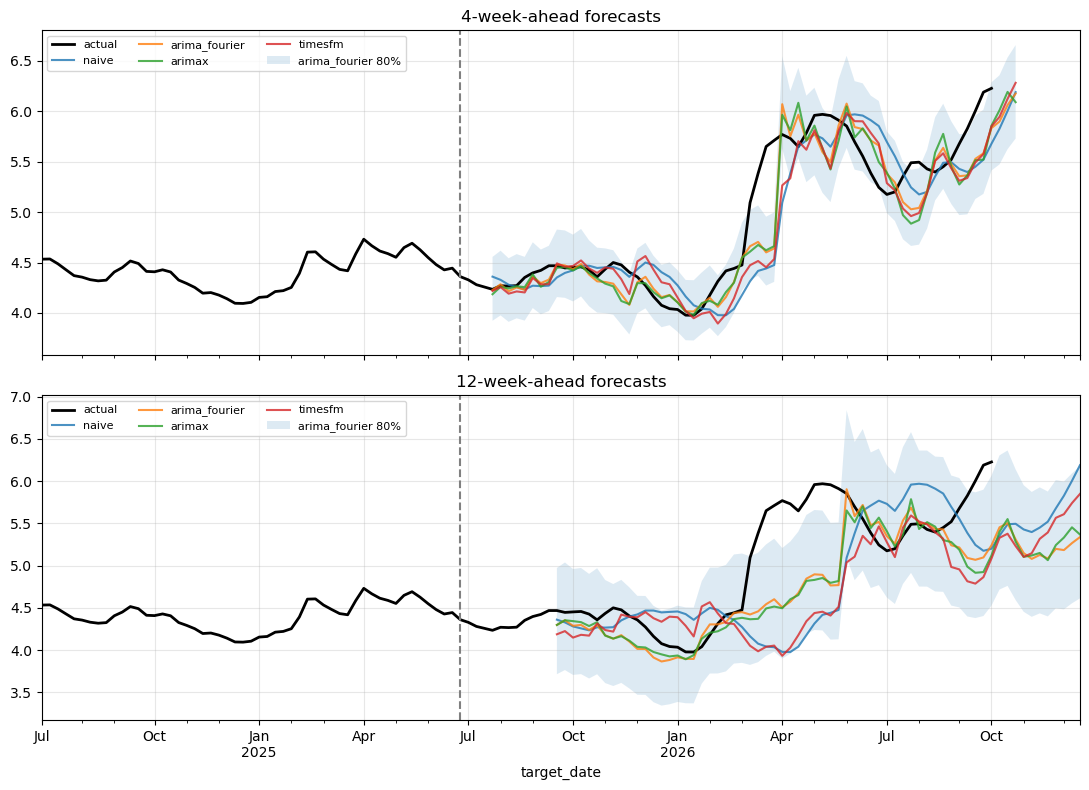

In [17]:
fig, axes = plt.subplots(len(SCORE_H), 1, figsize=(11, 8), sharex=True)
for ax, h in zip(axes, SCORE_H):
    df.loc["2024-07":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
    for m in ["naive", "arima_fourier", "arimax"] + (COMBO[1:] if ai_full else []):
        f = forecasts[m].query("horizon == @h").set_index("target_date")
        f["forecast"].plot(ax=ax, label=m, alpha=0.8)
    f = forecasts[best_conv].query("horizon == @h").set_index("target_date")
    ax.fill_between(f.index, f["lower80"], f["upper80"], alpha=0.15, label=f"{best_conv} 80%")
    ax.axvline(pd.Timestamp(TRAIN_END), color="grey", ls="--")
    ax.set_title(f"{h}-week-ahead forecasts"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 5. VAR、Granger causality、impulse response
用 training 期間的 Δlog Brent 與 Δlog 加州油價，AIC 選落後期數。Impulse response 以 Cholesky 排序（Brent 在前），換算成 **Brent 上漲 10%** 時加州油價的累積反應。

Lag order (AIC): 10
d_brent Granger-causes d_ca_gas?  F = 6.29, p = 0.0000
d_ca_gas Granger-causes d_brent?  F = 1.32, p = 0.2130


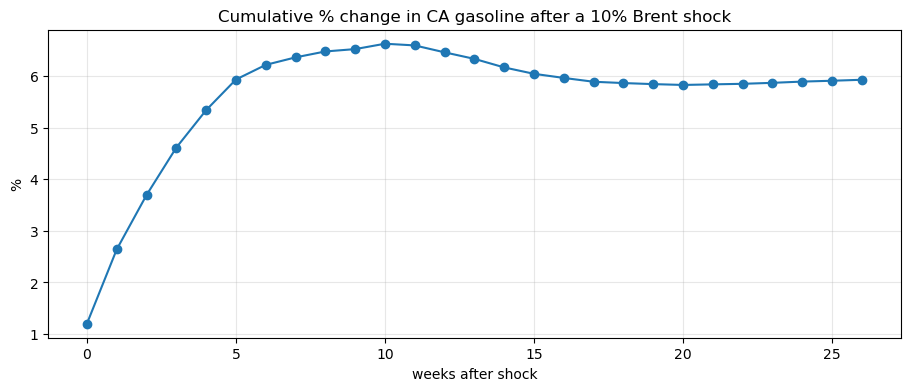

After 4 weeks: 5.34%, after 12 weeks: 6.46%, after 26 weeks: 5.93%


In [18]:
var_data = train[["log_brent", "log_ca_gas"]].diff().dropna()
var_data.columns = ["d_brent", "d_ca_gas"]
var_res = VAR(var_data).fit(maxlags=12, ic="aic")
print("Lag order (AIC):", var_res.k_ar)

for caused, causing in [("d_ca_gas", "d_brent"), ("d_brent", "d_ca_gas")]:
    t = var_res.test_causality(caused, [causing], kind="f")
    print(f"{causing} Granger-causes {caused}?  F = {t.test_statistic:.2f}, p = {t.pvalue:.4f}")

irf = var_res.irf(26)
oi = irf.orth_irfs  # [step, response, shock]
b, c = 0, 1         # column positions: d_brent, d_ca_gas
pass_through = pd.Series(np.cumsum(oi[:, c, b]) / oi[0, b, b] * 0.10, name="cum. response")
ax = (pass_through * 100).plot(marker="o", title="Cumulative % change in CA gasoline after a 10% Brent shock")
ax.set_xlabel("weeks after shock"); ax.set_ylabel("%"); plt.show()
print(f"After 4 weeks: {pass_through[4]:.2%}, after 12 weeks: {pass_through[12]:.2%}, after 26 weeks: {pass_through[26]:.2%}")

## 6. Rockets and feathers：非對稱 error-correction model

$$\Delta P_t = \alpha + \sum_{i=0}^{k} \beta_i^{+} \Delta C_{t-i}^{+} + \sum_{i=0}^{k} \beta_i^{-} \Delta C_{t-i}^{-} + \gamma (P_{t-1} - \theta C_{t-1}) + \varepsilon_t$$

- P = 加州油價（USD/gal），C = Brent（換算成 USD/gal = USD/bbl ÷ 42）
- Engle-Granger 兩步驟：先用水準回歸估 θ，再估 ECM（HAC 標準誤）
- **Wald test**：H0 = Σβ⁺ = Σβ⁻。拒絕且 Σβ⁺ > Σβ⁻ → 漲得快、跌得慢

In [19]:
K_ECM = 4
P, C = train["ca_gas"], train["brent"] / 42
lr = sm.OLS(P, sm.add_constant(C)).fit()
theta = lr.params["brent"]
ect = lr.resid

dC = C.diff()
ecm = pd.DataFrame({"dP": P.diff(), "ect_l1": ect.shift(1)})
for i in range(K_ECM + 1):
    ecm[f"dCpos_l{i}"] = dC.clip(lower=0).shift(i)
    ecm[f"dCneg_l{i}"] = dC.clip(upper=0).shift(i)
ecm = ecm.dropna()
ecm_res = sm.OLS(ecm["dP"], sm.add_constant(ecm.drop(columns="dP"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(f"Long-run pass-through theta = {theta:.3f} USD/gal per USD/gal of crude")
print(ecm_res.summary().tables[1])

pos = [f"dCpos_l{i}" for i in range(K_ECM + 1)]; neg = [f"dCneg_l{i}" for i in range(K_ECM + 1)]
R = np.zeros(len(ecm_res.params)); names = list(ecm_res.params.index)
for v in pos: R[names.index(v)] = 1
for v in neg: R[names.index(v)] = -1
wald = ecm_res.wald_test(R.reshape(1, -1), scalar=True)
print(f"\nSum beta+ = {ecm_res.params[pos].sum():.3f},  Sum beta- = {ecm_res.params[neg].sum():.3f}")
print(f"Wald test H0: Sum beta+ = Sum beta-   stat = {wald.statistic:.2f}, p = {wald.pvalue:.4f}")

Long-run pass-through theta = 1.210 USD/gal per USD/gal of crude
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.004      0.046      0.963      -0.008       0.009
ect_l1        -0.0054      0.006     -0.859      0.390      -0.018       0.007
dCpos_l0       0.4861      0.088      5.515      0.000       0.313       0.659
dCneg_l0       0.2502      0.058      4.312      0.000       0.136       0.364
dCpos_l1       0.3075      0.063      4.873      0.000       0.184       0.431
dCneg_l1       0.2776      0.037      7.599      0.000       0.206       0.349
dCpos_l2       0.1543      0.049      3.171      0.002       0.059       0.250
dCneg_l2       0.2488      0.049      5.101      0.000       0.153       0.344
dCpos_l3       0.0924      0.059      1.565      0.118      -0.023       0.208
dCneg_l3       0.1081      0.063      1.715      0.086      -0.015

## 7. AI vs 傳統模型（研究問題 3）

### 7.1 時間序列 foundation models
Chronos-Bolt、Chronos-2、TimesFM 2.5 都是 zero-shot：沒有用加州油價重新訓練，只把最近 512 週的油價當輸入。

**Look-ahead 檢查**：模型的發布日期是訓練資料的上限。發布日期在 test 期間（2025-07 之後）的模型，理論上可能看過部分 test 資料；Chronos-Bolt（2024-11）發布在 test 期間之前，是最乾淨的比較。

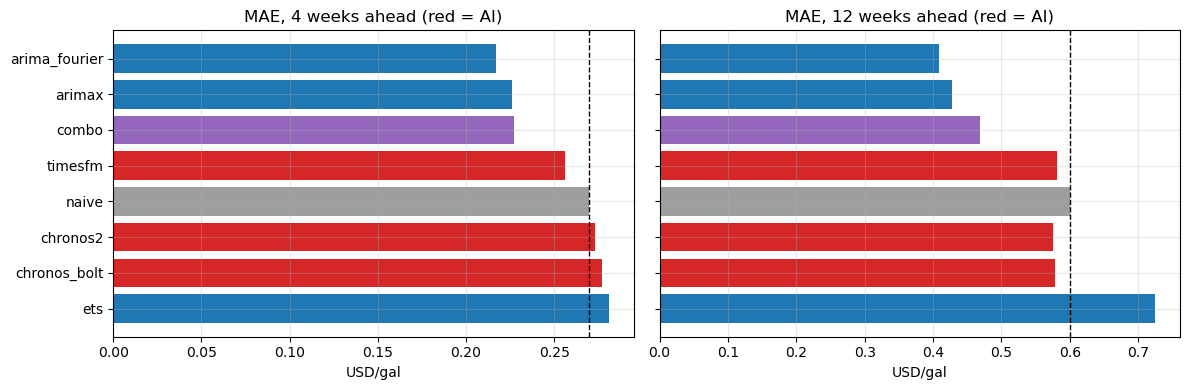

,horizon,model,type,MAE,Skill_vs_naive,Coverage80
0,4,arima_fourier,Conventional,0.217,0.804,0.810
1,4,arimax,Conventional,0.226,0.837,0.762
4,4,combo,Combination,0.227,0.840,0.825
7,4,timesfm,AI,0.256,0.948,0.746
6,4,naive,Benchmark,0.270,1.000,0.635
2,4,chronos2,AI,0.273,1.009,0.730
3,4,chronos_bolt,AI,0.277,1.025,0.683
5,4,ets,Conventional,0.281,1.039,0.841
8,12,arima_fourier,Conventional,0.409,0.682,0.745
9,12,arimax,Conventional,0.427,0.711,0.709


In [20]:
rows = []
for h in SCORE_H:
    mh = metrics.xs(h, level="horizon")
    for m in mh.index:
        if m == "snaive" or m.startswith("llm_"):
            continue
        kind = "AI" if is_ai(m) else "Benchmark" if m == "naive" else "Combination" if m == "combo" else "Conventional"
        rows.append({"horizon": h, "model": m, "type": kind,
                     "MAE": mh.loc[m, "MAE"], "Skill_vs_naive": mh.loc[m, "Skill_vs_naive"], "Coverage80": mh.loc[m, "Coverage80"]})
ai_vs = pd.DataFrame(rows).sort_values(["horizon", "MAE"])

fig, axes = plt.subplots(1, len(SCORE_H), figsize=(12, 4), sharey=True)
colors = {"AI": "#d62728", "Conventional": "#1f77b4", "Benchmark": "#9e9e9e", "Combination": "#9467bd"}
for ax, h in zip(axes, SCORE_H):
    d = ai_vs[ai_vs.horizon == h].sort_values("MAE", ascending=False)
    ax.barh(d["model"], d["MAE"], color=d["type"].map(colors))
    ax.axvline(d.loc[d.model == "naive", "MAE"].iloc[0], color="k", ls="--", lw=1)
    ax.set_title(f"MAE, {h} weeks ahead (red = AI)"); ax.set_xlabel("USD/gal")
plt.tight_layout(); plt.show()
ai_vs.round(3)

### 7.2 LLM 實驗（Claude、ChatGPT）
- **Experiment 1（anon）**：只看到最近 156 週、換算成指數（第一週 = 100）的數字，不知道是什麼序列、也沒有日期
- **Experiment 2（context）**：知道是加州油價，有日期、最近的 Brent 價格，以及**預測當天以前**的新聞摘要
- 兩個實驗的差距 = LLM 的準確度有多少來自「背景知識」而不是「看數字的模式」

LLM 只在 17 個預測日跑（每 4 週一次），所以這裡**只用這 17 天**比較所有模型，才公平。所有 prompt、模型版本、原始回應都記錄在 `results/llm_log.jsonl`。

In [21]:
llm_models = [m for m in forecasts if m.startswith("llm_")]
if not llm_models:
    print("No LLM forecasts yet. Set ANTHROPIC_API_KEY / OPENAI_API_KEY and run:\n"
          "  .venv-ai/bin/python llm/llm_experiments.py")
else:
    llm_dates = set(forecasts[llm_models[0]]["origin_date"])
    same = all_fc[all_fc["origin_date"].isin(llm_dates) & all_fc["horizon"].isin(SCORE_H)]
    keep = llm_models + ["naive", best_conv] + ai_full
    llm_table = (same[same.model.isin(keep)].assign(ae=lambda d: d.err.abs())
                 .pivot_table(index="model", columns="horizon", values="ae", aggfunc="mean").round(3)
                 .sort_values(SCORE_H[0]))
    llm_table.columns = [f"MAE h={h}" for h in llm_table.columns]
    print(f"MAE on the {len(llm_dates)} LLM forecast dates only")
    display(llm_table)
    for prov in sorted({m.split("_")[1] for m in llm_models}):
        a, c = f"llm_{prov}_anon", f"llm_{prov}_context"
        if a in llm_table.index and c in llm_table.index:
            gap = llm_table.loc[a] - llm_table.loc[c]
            print(f"{prov}: anon - context MAE = " + ", ".join(f"{k}: {v:+.3f}" for k, v in gap.items())
                  + "  (positive = background knowledge helps)")

No LLM forecasts yet. Set ANTHROPIC_API_KEY / OPENAI_API_KEY and run:
  .venv-ai/bin/python llm/llm_experiments.py


## 8. 情境預測：有事件 vs 沒有事件

同一個模型跑兩次：一次假設**沒有新事件**（baseline），一次假設**發生某個事件**，兩條預測的差距就是事件的效果。

**模型（ARDL，週變動）**

$$\Delta \log P_t = c + \sum_{i=1}^{4}\phi_i \Delta \log P_{t-i} + \sum_{k=0}^{8}\beta_k \Delta \log \text{Brent}_{t-k} + \text{季節項} + \delta_1 \text{Spike}_t + \delta_2 \text{Recovery}_t + \varepsilon_t$$

| 事件 | 怎麼放進模型 | 依據 |
|---|---|---|
| **戰爭 / 停火** | 改變未來的 **Brent 路徑** | 歷史資料：控制 Brent 後，戰爭期間油價沒有額外上漲，影響都透過原油 |
| **煉油廠突發事故**（大火、爆炸、停電） | **Spike**（第 1–3 週 = 1）+ **Recovery**（第 4–8 週 = 1） | 用 4 次歷史事故估計：油價先跳漲，再部分回落 |
| 煉油廠計畫性關閉 | 預設不放 | Phillips 66、Benicia 關廠當下測不到跳漲（提前一年宣布，市場已先反應） |

**為什麼情境分析不用 ARIMAX？** ARIMAX 只用 Brent 過去 4 週的變動，原油的影響也不會隨時間累積，會低估原油的影響（例如 Brent \$80 和 \$150，12 週後加州油價只差約 \$0.5）。這個模型把油價自己的落後項放在方程式裡，所以 Brent 和事故的衝擊會隨時間累積傳遞，比較適合做情境分析。預測區間用殘差 bootstrap 模擬 1,000 條路徑。

In [22]:
OUTAGES = {  # unplanned California refinery outages (first Monday on/after the event)
    "Chevron Richmond fire": "2012-08-06",
    "ExxonMobil Torrance power outage": "2012-10-01",
    "ExxonMobil Torrance explosion": "2015-02-23",
    "Chevron El Segundo fire": "2025-10-06",
}
SPIKE_W, RECOV_W = 3, 5     # weeks 1-3 prices jump, weeks 4-8 partly reverse
P_AR, Q_BRENT = 4, 8

def outage_dummies(index, starts):
    spike = pd.Series(0.0, index=index, name="outage_spike")
    rec = pd.Series(0.0, index=index, name="outage_recovery")
    for d in map(pd.Timestamp, starts):
        if d in index:
            i = index.get_loc(d)
            spike.iloc[i:i + SPIKE_W] = 1
            rec.iloc[i + SPIKE_W:i + SPIKE_W + RECOV_W] = 1
    return spike, rec

def seas_diff(dates):
    # First difference of the Fourier terms (the model is in weekly changes)
    t = ((dates - T0).days / 7).values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * t / PERIOD) - fn(2 * np.pi * k * (t - 1) / PERIOD)
                         for k in range(1, K_BEST + 1) for f, fn in (("ds", np.sin), ("dc", np.cos))}, index=dates)

def fit_ardl(data):
    dy, db = data["log_ca_gas"].diff(), data["log_brent"].diff()
    spike, rec = outage_dummies(data.index, OUTAGES.values())
    X = pd.concat([pd.DataFrame({f"dy_l{i}": dy.shift(i) for i in range(1, P_AR + 1)}),
                   pd.DataFrame({f"db_l{k}": db.shift(k) for k in range(Q_BRENT + 1)}),
                   seas_diff(data.index), spike, rec], axis=1)
    d = pd.concat([dy.rename("dy"), sm.add_constant(X)], axis=1).dropna()
    return sm.OLS(d["dy"], d.drop(columns="dy")).fit(cov_type="HAC", cov_kwds={"maxlags": 4})


def event_scenario(data=df, h=H, brent_path=None, outage_at=None, res=None, n_sims=1000, seed=0):
    # brent_path: future weekly Brent (USD/bbl), length h. None = no new event (Brent stays flat).
    # outage_at:  horizon week (1..h) when a new refinery outage starts. None = no outage.
    # Outages that started before the origin keep playing out automatically.
    res = fit_ardl(data) if res is None else res
    b = res.params
    fut = future_dates(data, h)
    future_lb = np.log(brent_path) if brent_path is not None else data["log_brent"].iloc[-1]
    db = pd.concat([data["log_brent"], pd.Series(future_lb, index=fut)]).diff()
    starts = list(OUTAGES.values()) + ([fut[outage_at - 1]] if outage_at else [])
    spike, rec = outage_dummies(data.index.append(fut), starts)

    det = np.full(h, b["const"])   # deterministic part of each future weekly change
    for k in range(Q_BRENT + 1):
        det += b[f"db_l{k}"] * db.shift(k).loc[fut].values
    S = seas_diff(fut)
    for c in S:
        det += b[c] * S[c].values
    det += b["outage_spike"] * spike.loc[fut].values + b["outage_recovery"] * rec.loc[fut].values

    phi = b[[f"dy_l{i}" for i in range(1, P_AR + 1)]].values
    lags = np.tile(data["log_ca_gas"].diff().iloc[-P_AR:].values[::-1], (n_sims, 1))  # most recent first
    shocks = np.random.default_rng(seed).choice(res.resid.values, size=(n_sims, h))
    paths = np.zeros((n_sims, h))
    for s in range(h):
        paths[:, s] = det[s] + lags @ phi + shocks[:, s]
        lags = np.column_stack([paths[:, s], lags[:, :-1]])
    lvl = data["log_ca_gas"].iloc[-1] + paths.cumsum(axis=1)
    q = np.exp(np.percentile(lvl, [10, 50, 90], axis=0))
    return pd.DataFrame({"forecast": q[1], "lower80": q[0], "upper80": q[2]}, index=fut)


ardl_full = fit_ardl(df)
key = ["outage_spike", "outage_recovery"]
print(pd.DataFrame({"coef (%/week)": ardl_full.params[key] * 100, "p": ardl_full.pvalues[key]}).round(3))
print(f"Sum of Brent coefficients (short-run pass-through): {ardl_full.params.filter(like='db_l').sum():.3f}")

                 coef (%/week)      p
outage_spike             1.232  0.084
outage_recovery         -0.506  0.182
Sum of Brent coefficients (short-run pass-through): 0.274


### 8.1 模型校準檢查：單一事件的效果
先看「只有一個事件」時，模型預測的加州油價會比 baseline 高多少，確認數字合理（例如 Brent 漲 10%，VAR 的結果是 4 週後約 +5%）。

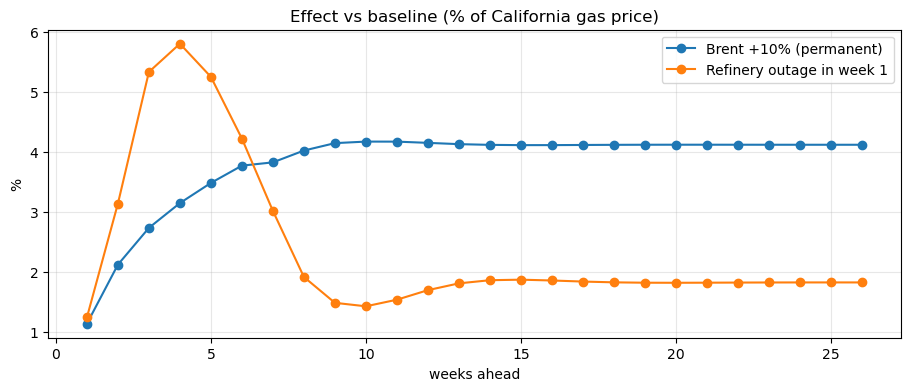

,Brent +10% (permanent),Refinery outage in week 1
1,1.14,1.24
2,2.12,3.14
4,3.15,5.80
8,4.02,1.92
12,4.15,1.70
26,4.12,1.82


In [23]:
last_brent = df["brent"].iloc[-1]
base = event_scenario(h=26)["forecast"]
check = pd.DataFrame({
    "Brent +10% (permanent)": event_scenario(h=26, brent_path=[last_brent * 1.1] * 26)["forecast"] / base - 1,
    "Refinery outage in week 1": event_scenario(h=26, outage_at=1)["forecast"] / base - 1,
})
check.index = range(1, 27)
ax = (check * 100).plot(marker="o", title="Effect vs baseline (% of California gas price)")
ax.set_xlabel("weeks ahead"); ax.set_ylabel("%"); plt.show()
(check.loc[[1, 2, 4, 8, 12, 26]] * 100).round(2)

### 8.2 事件情境：戰爭、煉油廠事故、停火

情境的大小參考歷史：2026 伊朗戰爭第一個月 Brent 漲約 55%；4 月停火後到 7 月，Brent 從約 118 跌到約 70（約 −40%）。可以自行修改 `SCENARIOS`。

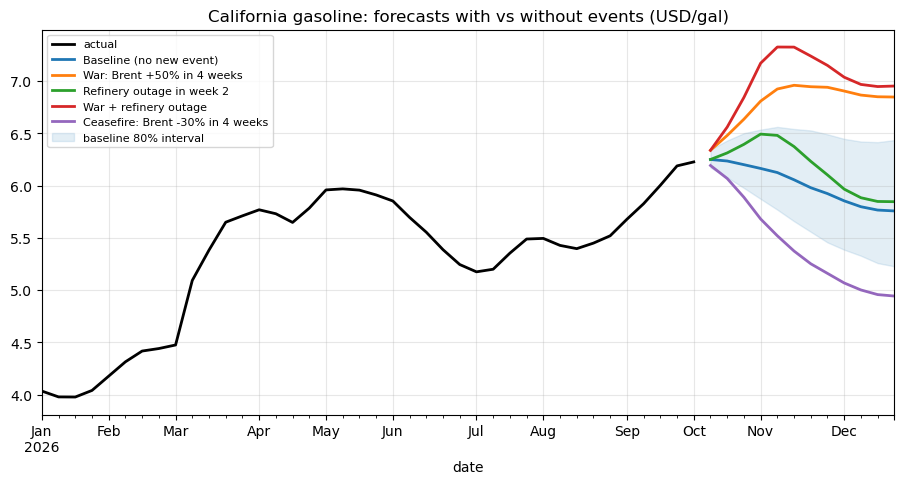

forecast             vs baseline            
weeks ahead                            4     8     12          4     8     12
scenario                                                                     
Baseline (no new event)              6.16  5.92  5.76        0.00  0.00  0.00
Ceasefire: Brent -30% in 4 weeks     5.68  5.16  4.94       -0.48 -0.76 -0.81
Refinery outage in week 2            6.49  6.10  5.85        0.33  0.18  0.09
War + refinery outage                7.17  7.15  6.95        1.01  1.23  1.20
War: Brent +50% in 4 weeks           6.81  6.94  6.85        0.64  1.02  1.09

In [24]:
def brent_ramp(mult, weeks, h=H):
    # Brent moves to last_brent * mult over `weeks` weeks, then stays there
    return last_brent * np.r_[np.linspace(1, mult, weeks + 1)[1:], np.repeat(mult, h - weeks)]

SCENARIOS = {
    "Baseline (no new event)": {},
    "War: Brent +50% in 4 weeks": dict(brent_path=brent_ramp(1.5, 4)),
    "Refinery outage in week 2": dict(outage_at=2),
    "War + refinery outage": dict(brent_path=brent_ramp(1.5, 4), outage_at=2),
    "Ceasefire: Brent -30% in 4 weeks": dict(brent_path=brent_ramp(0.7, 4)),
}
scen = {name: event_scenario(res=ardl_full, **kw) for name, kw in SCENARIOS.items()}  # same seed -> same shocks

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for name, s in scen.items():
    s["forecast"].plot(ax=ax, lw=2, label=name)
b0 = scen["Baseline (no new event)"]
ax.fill_between(b0.index, b0["lower80"], b0["upper80"], color="C0", alpha=0.12, label="baseline 80% interval")
ax.set_title("California gasoline: forecasts with vs without events (USD/gal)"); ax.legend(fontsize=8); plt.show()

rows = []
for name, s in scen.items():
    for w in (4, 8, 12):
        rows.append({"scenario": name, "weeks ahead": w, "forecast": s["forecast"].iloc[w - 1],
                     "vs baseline": s["forecast"].iloc[w - 1] - b0["forecast"].iloc[w - 1],
                     "80% interval": f"{s['lower80'].iloc[w - 1]:.2f} - {s['upper80'].iloc[w - 1]:.2f}"})
scen_table = pd.DataFrame(rows).pivot(index="scenario", columns="weeks ahead", values=["forecast", "vs baseline"]).round(2)
scen_table.to_csv(RES_DIR / "event_scenarios.csv")
scen_table

### 8.3 Brent 價格情境 `scenario()`（給 dashboard 的 scenario tool 用）
使用者輸入未來每週的 Brent 價格（USD/桶）→ 回傳加州油價預測與 80% 區間。
Proposal 原本寫用 ARIMAX，這裡改用上面的模型，原因見 8. 的說明。

「Brent flat」= 原油維持在**現在的價格**不變；其他情境是原油在 4 週內慢慢變成目標價格，之後維持不變。

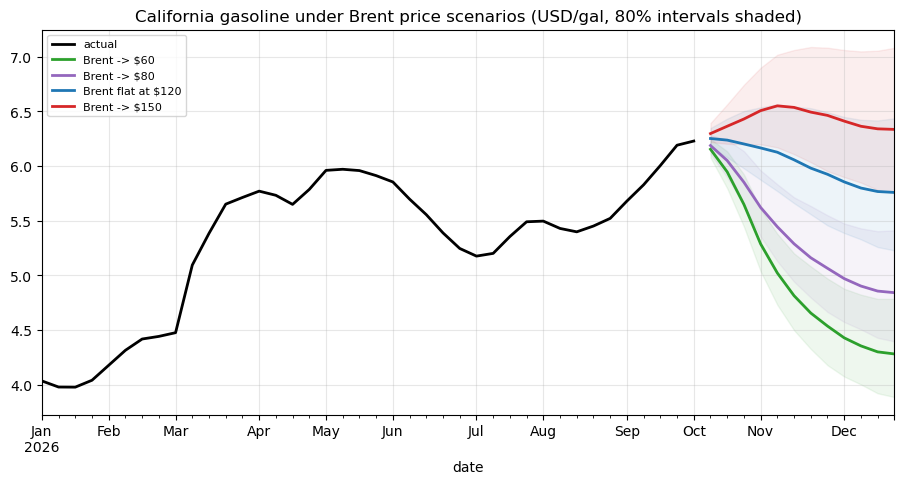

,4 weeks,8 weeks,12 weeks,12-week 80% interval
Brent -> $60,5.286412,4.535536,4.280591,3.89 - 4.78
Brent -> $80,5.620017,5.063701,4.840781,4.40 - 5.41
Brent flat at $120,6.164047,5.923107,5.757179,5.23 - 6.43
Brent -> $150,6.505131,6.461612,6.333599,5.75 - 7.08


In [25]:
def scenario(brent_path, outage_at=None, data=df):
    # brent_path: future weekly Brent prices (USD/bbl). outage_at: optional week of a refinery outage.
    # Returns CA gasoline forecast (USD/gal) with an 80% interval, indexed by date.
    res = ardl_full if data is df else None
    return event_scenario(data, h=len(brent_path), brent_path=np.asarray(brent_path, float),
                          outage_at=outage_at, res=res)

BRENT_TARGETS = [60, 80, round(last_brent), 150]   # USD/bbl
price_scen = {(f"Brent flat at ${t}" if t == round(last_brent) else f"Brent -> ${t}"):
              scenario(brent_ramp(t / last_brent, 4)) for t in BRENT_TARGETS}

fig, ax = plt.subplots(figsize=(11, 5))
df.loc["2026-01":, "ca_gas"].plot(ax=ax, color="k", lw=2, label="actual")
for (name, s), color in zip(price_scen.items(), ["C2", "C4", "C0", "C3"]):
    s["forecast"].plot(ax=ax, lw=2, color=color, label=name)
    ax.fill_between(s.index, s["lower80"], s["upper80"], color=color, alpha=0.08)
ax.set_title("California gasoline under Brent price scenarios (USD/gal, 80% intervals shaded)")
ax.legend(fontsize=8); plt.show()

brent_table = pd.DataFrame({name: {f"{w} weeks": s["forecast"].iloc[w - 1] for w in (4, 8, 12)}
                            | {"12-week 80% interval": f"{s['lower80'].iloc[-1]:.2f} - {s['upper80'].iloc[-1]:.2f}"}
                            for name, s in price_scen.items()}).T
brent_table.to_csv(RES_DIR / "brent_scenarios.csv")
brent_table

### 8.4 這個模型的 baseline 預測準不準？
把 `event_scenario()` 的 baseline（沒有新事件、Brent 不變）也放進同一個 rolling-origin backtest，和其他模型比較。如果準確度跟 ARIMA 差不多，它的情境預測就比較可信。

In [26]:
def ardl_ff(train, h):
    f = event_scenario(train, h, n_sims=500)
    f.index = range(1, h + 1)
    return f

forecasts["ardl"] = backtest("ardl", ardl_ff)
all_fc, metrics = evaluate(forecasts)
metrics.to_csv(RES_DIR / "metrics.csv")
metrics.sort_values(["horizon", "MAE"])

  ardl: origin 1/66 2025-06-30


  ardl: origin 21/66 2025-11-17


  ardl: origin 41/66 2026-04-06


  ardl: origin 61/66 2026-08-24
  ardl: origin 66/66 2026-09-28


n    MAE   RMSE    MAPE  Coverage80  Skill_vs_naive
horizon model                                                              
4       arima_fourier  63  0.217  0.312   4.100       0.810           0.804
        arimax         63  0.226  0.326   4.249       0.762           0.837
        combo          63  0.227  0.328   4.306       0.825           0.840
        ardl           63  0.235  0.326   4.540       0.683           0.868
        timesfm        63  0.256  0.361   4.909       0.746           0.948
        naive          63  0.270  0.384   5.233       0.635           1.000
        chronos2       63  0.273  0.384   5.205       0.730           1.009
        chronos_bolt   63  0.277  0.384   5.308       0.683           1.025
        ets            63  0.281  0.378   5.374       0.841           1.039
        snaive         63  0.631  0.848  11.421       0.841           2.335
12      arima_fourier  55  0.409  0.581   7.511       0.745           0.682
        arimax         55  0.427  0.609   7.775       0.709           0.711
        combo          55  0.469  0.690   8.501       0.727           0.782
        ardl           55  0.476  0.638   8.694       0.636           0.793
        chronos2       55  0.575  0.818  10.566       0.673           0.959
        chronos_bolt   55  0.579  0.829  10.592       0.691           0.966
        timesfm        55  0.582  0.820  10.697       0.709           0.970
        naive          55  0.600  0.812  11.109       0.673           1.000
        snaive         55  0.715  0.907  12.895       0.818           1.192
        ets            55  0.725  0.904  13.502       0.836           1.208

## 輸出檔案
- `forecasts/<model>.csv`：每個模型的預測（proposal 指定的統一格式），給 Member 3 評分、Member 6 的 dashboard 讀取
- `results/metrics.csv`：MAE / RMSE / MAPE / skill / coverage
- `results/dm_tests.csv`：Diebold-Mariano 檢定
- `results/event_scenarios.csv`：有事件 vs 沒有事件的情境預測
- `results/brent_scenarios.csv`：Brent \$60 / \$80 / 現價 / \$150 的情境預測

**注意**：test 期間（2025-07 之後）包含 Phillips 66 關廠、Chevron 大火和 2026 伊朗戰爭，這些事件的 dummy 在 rolling origin 初期還沒有變化，所以會被自動排除，等事件發生後才會進入模型。